---
## 1. Import Libraries & Load Dataset

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Load dataset
df = pd.read_csv("student_grades.csv")
SUBJECTS = ["math", "science", "cs", "band", "english", "history", "spanish", "physed"]

print(f"Loaded {df.shape[0]} student records across {len(SUBJECTS)} subjects.")
df.head()

Loaded 100 student records across 8 subjects.


,student_id,math,science,cs,band,english,history,spanish,physed
0,1,46,48,50,74,34,44,39,73
1,2,66,65,65,66,74,80,75,63
2,3,55,53,50,76,71,72,76,71
3,4,53,57,53,80,77,77,85,82
4,5,55,62,58,67,82,77,78,60


---
## 2. Feature Standardization & Baseline Cluster Assignment

In [4]:
# Standardize the 8 numeric subject features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[SUBJECTS])

# Consistent 4-cluster K-Means baseline
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

PROFILE_MAP = {
    0: "Humanities-Focused",
    1: "Humanities & Electives Leaders",
    2: "At-Risk Students",
    3: "High-Achieving All-Rounders"
}
df["Profile"] = df["Cluster"].map(PROFILE_MAP)

print("Cluster Distribution:")
print(df["Profile"].value_counts())

Cluster Distribution:
Profile
At-Risk Students                  44
Humanities-Focused                25
Humanities & Electives Leaders    22
High-Achieving All-Rounders        9
Name: count, dtype: int64


---
## 3. t-SNE Hyperparameter Tuning — Perplexity Sweep


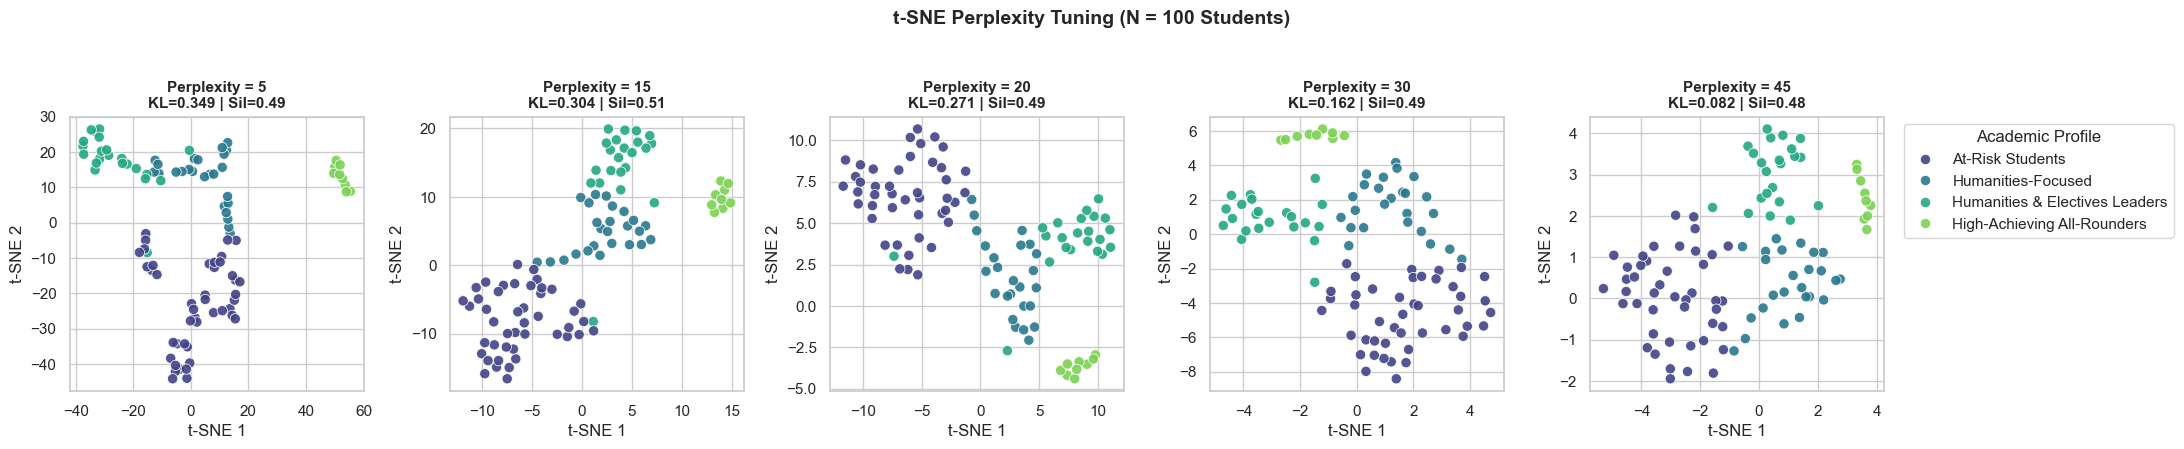

--- Perplexity Tuning Metrics ---


,Perplexity,KL_Divergence,Silhouette_2D
0,5,0.3494,0.4886
1,15,0.3037,0.5088
2,20,0.2709,0.4852
3,30,0.1621,0.4879
4,45,0.0824,0.4813


In [5]:
perplexities = [5, 15, 20, 30, 45]
perp_results = []

fig, axes = plt.subplots(1, len(perplexities), figsize=(22, 4.3))

for ax, perp in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate="auto",
        init="pca",
        random_state=RANDOM_STATE
    )
    emb = tsne.fit_transform(X_scaled)
    sil = silhouette_score(emb, df["Cluster"])
    perp_results.append({
        "Perplexity": perp,
        "KL_Divergence": round(float(tsne.kl_divergence_), 4),
        "Silhouette_2D": round(float(sil), 4)
    })

    sns.scatterplot(
        x=emb[:, 0], y=emb[:, 1],
        hue=df["Profile"], palette="viridis",
        s=55, alpha=0.9, ax=ax, legend=(perp == perplexities[-1])
    )
    ax.set_title(f"Perplexity = {perp}\nKL={tsne.kl_divergence_:.3f} | Sil={sil:.2f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

axes[-1].legend(title="Academic Profile", bbox_to_anchor=(1.04, 1), loc="upper left")
plt.suptitle("t-SNE Perplexity Tuning (N = 100 Students)", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

perp_df = pd.DataFrame(perp_results)
print("--- Perplexity Tuning Metrics ---")
perp_df

---
## 4. t-SNE Hyperparameter Tuning — Learning Rate Sweep

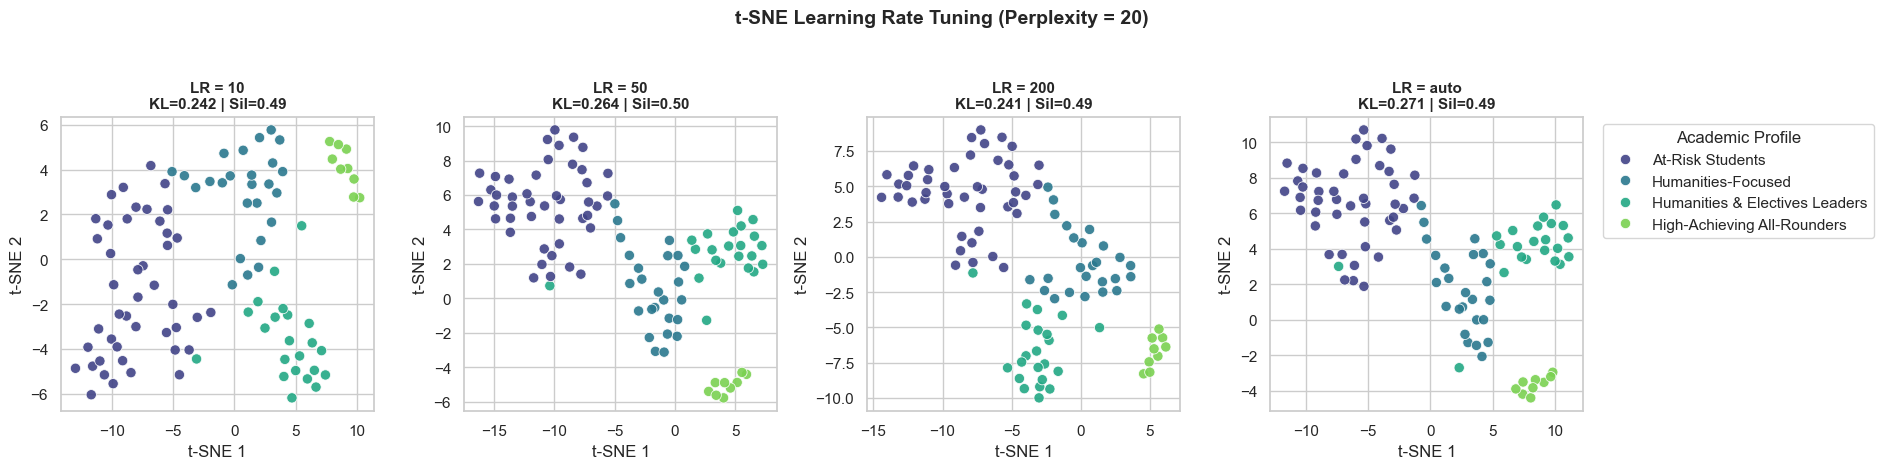

--- Learning Rate Tuning Metrics ---


,Learning_Rate,KL_Divergence,Silhouette_2D
0,10,0.2416,0.4884
1,50,0.2636,0.4990
2,200,0.2415,0.4906
3,auto,0.2709,0.4852


In [6]:
learning_rates = [10, 50, 200, "auto"]
lr_results = []

fig, axes = plt.subplots(1, len(learning_rates), figsize=(19, 4.5))

for ax, lr in zip(axes, learning_rates):
    tsne = TSNE(
        n_components=2,
        perplexity=20,
        learning_rate=lr,
        init="pca",
        random_state=RANDOM_STATE
    )
    emb = tsne.fit_transform(X_scaled)
    sil = silhouette_score(emb, df["Cluster"])
    lr_results.append({
        "Learning_Rate": str(lr),
        "KL_Divergence": round(float(tsne.kl_divergence_), 4),
        "Silhouette_2D": round(float(sil), 4)
    })

    sns.scatterplot(
        x=emb[:, 0], y=emb[:, 1],
        hue=df["Profile"], palette="viridis",
        s=55, alpha=0.9, ax=ax, legend=(lr == learning_rates[-1])
    )
    ax.set_title(f"LR = {lr}\nKL={tsne.kl_divergence_:.3f} | Sil={sil:.2f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

axes[-1].legend(title="Academic Profile", bbox_to_anchor=(1.04, 1), loc="upper left")
plt.suptitle("t-SNE Learning Rate Tuning (Perplexity = 20)", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

lr_df = pd.DataFrame(lr_results)
print("--- Learning Rate Tuning Metrics ---")
lr_df

---
## 5. Final Optimal t-SNE & Optional UMAP Embedding

In [7]:
# Optimal 2D t-SNE Embedding
tsne_opt = TSNE(
    n_components=2,
    perplexity=20,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)
X_tsne_opt = tsne_opt.fit_transform(X_scaled)
df["tSNE_1"] = X_tsne_opt[:, 0]
df["tSNE_2"] = X_tsne_opt[:, 1]

# Optional UMAP Embedding (graceful fallback if umap-learn is not installed)
try:
    import umap
    umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)
    X_umap = umap_model.fit_transform(X_scaled)
    df["UMAP_1"] = X_umap[:, 0]
    df["UMAP_2"] = X_umap[:, 1]
    HAS_UMAP = True
    print("UMAP embedding computed successfully.")
except ImportError:
    HAS_UMAP = False
    print("umap-learn is not installed. Run `pip install umap-learn` to include UMAP.")

UMAP embedding computed successfully.


---
## 6. Comparative Visual Analytics: Linear (PCA) vs. Non-Linear (t-SNE / UMAP)

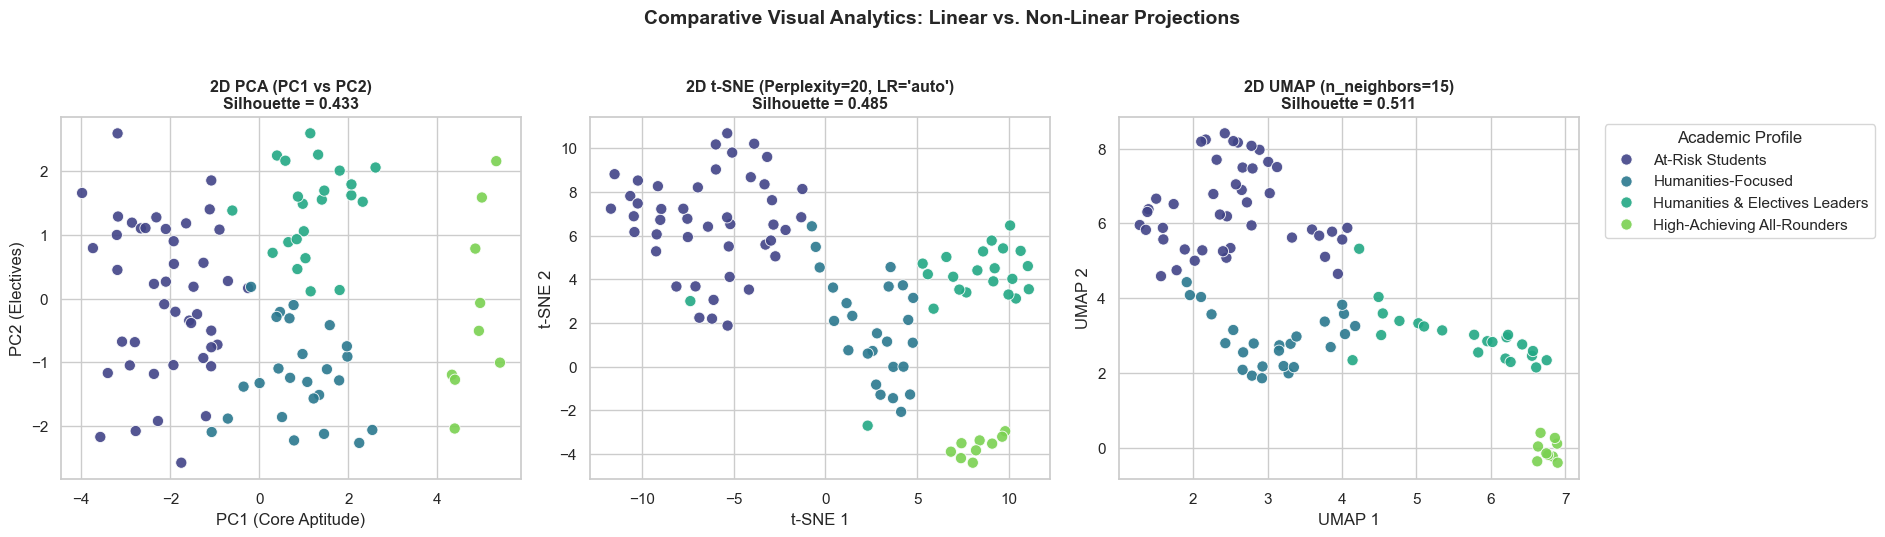

--- Quantitative Embedding Comparison ---


,Method,2D_Silhouette_Score
0,2D PCA (PC1 vs PC2),0.4333
1,"2D t-SNE (Perplexity=20, LR='auto')",0.4852
2,2D UMAP (n_neighbors=15),0.5115


In [8]:
# Compute 2D & 3D PCA for direct side-by-side comparison
pca_3d = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca = pca_3d.fit_transform(X_scaled)
df["PC1"], df["PC2"], df["PC3"] = X_pca[:, 0], X_pca[:, 1], X_pca[:, 2]

# Build comparison list
comparisons = [
    ("2D PCA (PC1 vs PC2)", X_pca[:, :2], "PC1 (Core Aptitude)", "PC2 (Electives)"),
    ("2D t-SNE (Perplexity=20, LR='auto')", X_tsne_opt, "t-SNE 1", "t-SNE 2")
]

if HAS_UMAP:
    comparisons.append(("2D UMAP (n_neighbors=15)", X_umap, "UMAP 1", "UMAP 2"))
else:
    comparisons.append(("2D PCA (PC1 vs PC3)", X_pca[:, [0, 2]], "PC1 (Core Aptitude)", "PC3 (STEM vs Humanities)"))

# Side-by-side scatter plots
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
benchmark_rows = []

for i, (title, emb, xlabel, ylabel) in enumerate(comparisons):
    sil = silhouette_score(emb, df["Cluster"])
    benchmark_rows.append({"Method": title, "2D_Silhouette_Score": round(float(sil), 4)})

    sns.scatterplot(
        x=emb[:, 0], y=emb[:, 1],
        hue=df["Profile"], palette="viridis",
        s=65, alpha=0.9, ax=axes[i], legend=(i == 2)
    )
    axes[i].set_title(f"{title}\nSilhouette = {sil:.3f}", fontsize=11.5, fontweight="bold")
    axes[i].set_xlabel(xlabel)
    axes[i].set_ylabel(ylabel)

axes[2].legend(title="Academic Profile", bbox_to_anchor=(1.04, 1), loc="upper left")
plt.suptitle("Comparative Visual Analytics: Linear vs. Non-Linear Projections", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print("--- Quantitative Embedding Comparison ---")
pd.DataFrame(benchmark_rows)

In [9]:
# Interactive 2D t-SNE Plot (Plotly — hover to inspect individual student grades)
fig_tsne = px.scatter(
    df,
    x="tSNE_1", y="tSNE_2",
    color="Profile",
    hover_data=["student_id"] + SUBJECTS,
    title="Interactive 2D t-SNE Student Academic Profiles (Perplexity = 20)",
    labels={"tSNE_1": "t-SNE Dimension 1", "tSNE_2": "t-SNE Dimension 2"}
)
fig_tsne.update_traces(marker=dict(size=9, line=dict(width=0.6, color="white")))
fig_tsne.show()